# Dữ liệu bệnh tiểu đường Pima Indians
**Nguồn trong đề:** Lab 1 — bài tập 1.1.4 và 1.2

Notebook độc lập cho một tập dữ liệu; code lấy từ các ô tương ứng của notebook Lab1 (giữ nguyên, ô nào chỉnh có ghi `# [Chỉnh]`).

In [1]:
# Thư viện dùng chung (đề import rải rác ở nhiều ô; gom lại để notebook chạy độc lập)
import os
if os.path.basename(os.getcwd()) == 'notebooks':   # chạy notebook từ thư mục notebooks/ thì lùi ra thư mục gốc chứa data/
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
diabetes = pd.read_csv("data/diabetes.csv")
print(diabetes.shape)
diabetes.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
diabetes.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [4]:
# Trong dữ liệu Pima, giá trị 0 ở các cột dưới đây thực chất là dữ liệu thiếu
cols0 = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
print((diabetes[cols0] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [5]:
# Xử lý dữ liệu thiếu: thay 0 bằng NaN rồi điền bằng median của từng cột
diabetes_clean = diabetes.copy()
diabetes_clean[cols0] = diabetes_clean[cols0].replace(0, np.nan)
diabetes_clean[cols0] = diabetes_clean[cols0].fillna(diabetes_clean[cols0].median())
diabetes_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,121.656250,30.438286,44.000,99.75000,117.0000,140.25000,199.00
BloodPressure,768.0,72.386719,12.096642,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,768.0,29.108073,8.791221,7.000,25.00000,29.0000,32.00000,99.00
Insulin,768.0,140.671875,86.383060,14.000,121.50000,125.0000,127.25000,846.00
BMI,768.0,32.455208,6.875177,18.200,27.50000,32.3000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [6]:
print("Phân bố nhãn Outcome:"); print(diabetes['Outcome'].value_counts())
print()
print("Trung bình theo nhóm Outcome:")
diabetes_clean.groupby('Outcome').mean().T

Phân bố nhãn Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64

Trung bình theo nhóm Outcome:


Outcome,0,1
Pregnancies,3.298000,4.865672
Glucose,110.682000,142.130597
BloodPressure,70.920000,75.123134
SkinThickness,27.726000,31.686567
Insulin,127.792000,164.701493
BMI,30.885600,35.383582
DiabetesPedigreeFunction,0.429734,0.550500
Age,31.190000,37.067164


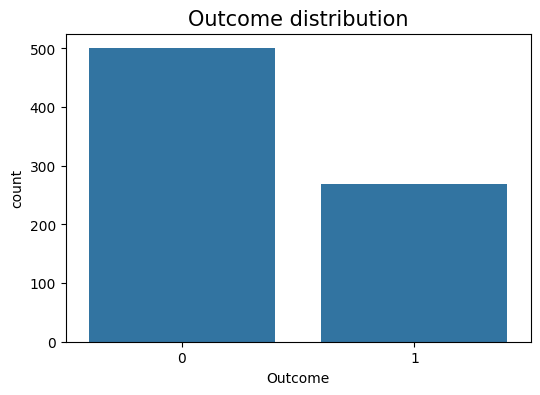

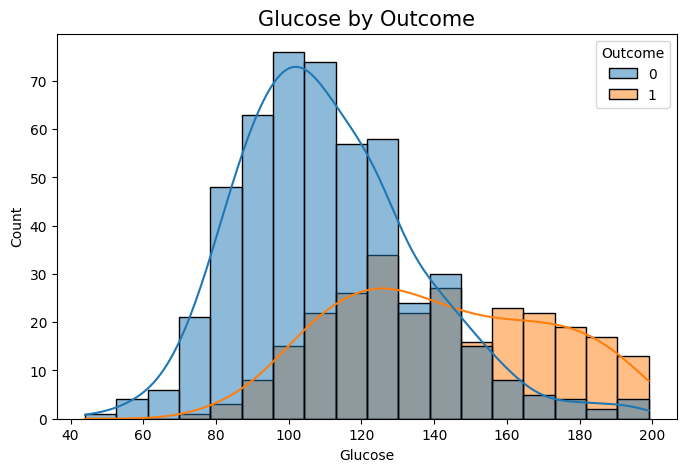

In [7]:
diabetes = pd.read_csv("data/diabetes.csv")
cols0 = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
diabetes[cols0] = diabetes[cols0].replace(0, np.nan)
diabetes[cols0] = diabetes[cols0].fillna(diabetes[cols0].median())

# 1. Số lượng người bệnh / không bệnh
plt.figure(figsize=(6,4))
ax = sns.countplot(data=diabetes, x='Outcome')
ax.set_title('Outcome distribution', fontsize=15)
plt.show()

# 2. Histogram Glucose theo Outcome
plt.figure(figsize=(8,5))
ax = sns.histplot(data=diabetes, x='Glucose', hue='Outcome', kde=True)
ax.set_title('Glucose by Outcome', fontsize=15)
plt.show()

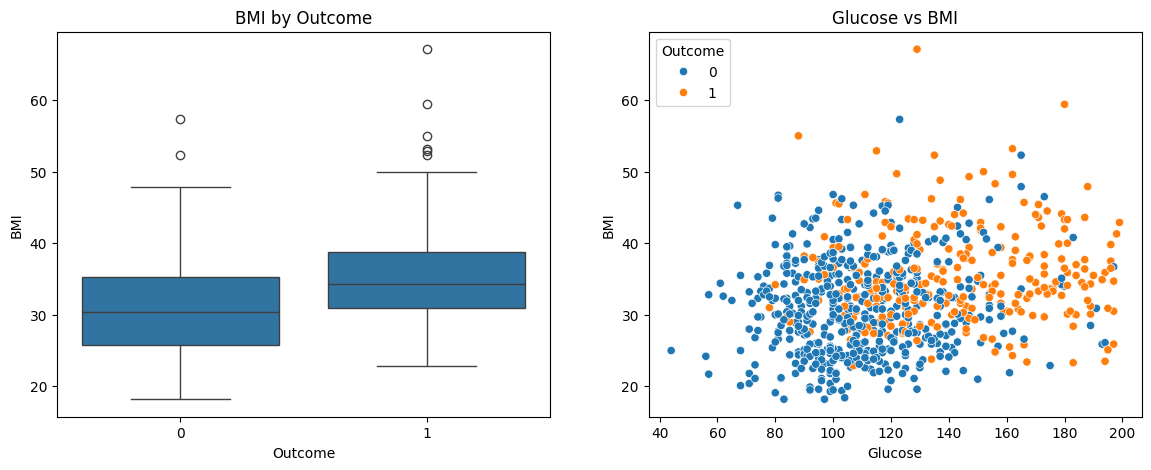

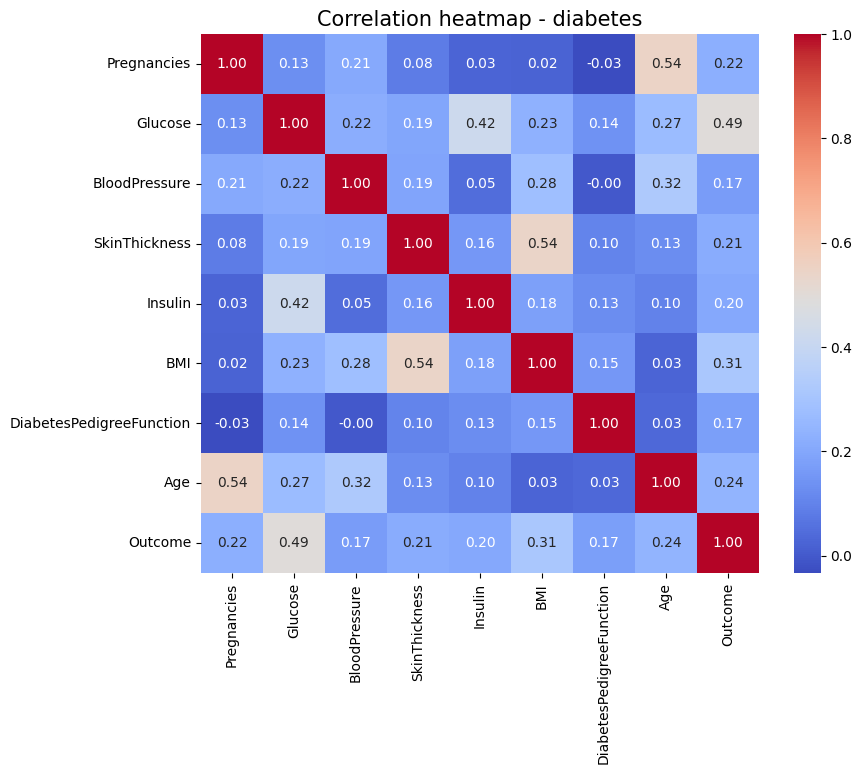

In [8]:
# 3. Boxplot BMI theo Outcome và scatter Glucose - BMI
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.boxplot(data=diabetes, x='Outcome', y='BMI', ax=axes[0]).set_title('BMI by Outcome')
sns.scatterplot(data=diabetes, x='Glucose', y='BMI', hue='Outcome', ax=axes[1]).set_title('Glucose vs BMI')
plt.show()

# 4. Heatmap tương quan
plt.figure(figsize=(9,7))
ax = sns.heatmap(diabetes.corr(), annot=True, fmt='.2f', cmap='coolwarm')
ax.set_title('Correlation heatmap - diabetes', fontsize=15)
plt.show()